# 14 — Como funciona e como se comporta a Regressão Logística

Este notebook avalia **o artefato ativo** `models/pipeline_final.joblib`: Regressão Logística L2 (`C=1.0`, `class_weight="balanced"`) usando somente `tmax_enchimento` (média da temperatura máxima diária entre dezembro e fevereiro). A unidade de análise é município × safra, em nove municípios. O alvo é `quebra_safra`, definido pela regra de tendência histórica descrita nos notebooks anteriores.

A regra congelada é probabilidade do modelo ≥ **0,45**, equivalente a `tmax_enchimento` ≥ **28,34 °C**. A probabilidade é um **índice de risco**, não uma chance calibrada de quebra.

## Como ler as avaliações

- **Backtest expansivo histórico:** para cada safra avaliada no treino, o pipeline é re-ajustado apenas com safras estritamente anteriores (mínimo de oito safras anteriores). A regra de corte 0,45 é mantida fixa para refletir o modelo ativo.
- **Cautela metodológica:** o corte 0,45 foi escolhido anteriormente usando validação do período de treino como um todo. Assim, este backtest é um diagnóstico temporal do ajuste do modelo, **não um backtest de política totalmente aninhado**: o corte não foi recalibrado apenas com dados disponíveis em cada origem histórica. As métricas do backtest são diagnósticas, não uma estimativa independente de desempenho futuro.
- **Teste temporal congelado (2019–2024):** esta é a avaliação fora do tempo principal. O teste não é usado para treinar, alterar o modelo nem escolher o limiar.

O modelo permanece **experimental e não aprovado para decisão operacional**. O objetivo aqui é mostrar o que ele faz, onde acerta e onde falha, sem esconder falsos alarmes ou quebras não detectadas.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

sns.set_theme(style="whitegrid", context="notebook")
PASTA = Path.cwd().resolve()
while not (PASTA / "models" / "pipeline_final.joblib").is_file():
    if PASTA.parent == PASTA:
        raise FileNotFoundError("Abra/execute este notebook a partir de uma pasta dentro do repositório SojaRisco.")
    PASTA = PASTA.parent

CAMINHO_BASE = PASTA / "data" / "processed" / "dados_modelo_s4.csv"
CAMINHO_MODELO = PASTA / "models" / "pipeline_final.joblib"
CAMINHO_LIMIAR = PASTA / "models" / "limiar_congelado.json"
if not CAMINHO_BASE.is_file() or not CAMINHO_LIMIAR.is_file():
    raise FileNotFoundError("Faltam a base processada ou o JSON do limiar congelado.")

TARGET = "quebra_safra"
FEATURES = ["tmax_enchimento"]
CUSTO_FN, CUSTO_FP = 5, 1
MIN_SAFRAS_ANTERIORES = 8
config_limiar = json.loads(CAMINHO_LIMIAR.read_text(encoding="utf-8"))
LIMIAR = float(config_limiar["limiar_otimo"])
LIMIAR_C = float(config_limiar["limiar_celsius"])
assert config_limiar["features"] == FEATURES
assert LIMIAR == 0.45 and np.isclose(LIMIAR_C, 28.34)

dados = pd.read_csv(CAMINHO_BASE).sort_values(["cod_municipio", "safra"]).reset_index(drop=True)
colunas_obrigatorias = {"cod_municipio", "municipio", "safra", "split", TARGET, *FEATURES}
faltantes = colunas_obrigatorias - set(dados.columns)
if faltantes:
    raise ValueError(f"Colunas ausentes na base: {sorted(faltantes)}")
if dados.duplicated(["cod_municipio", "safra"]).any():
    raise ValueError("A chave município-safra está duplicada.")
if dados[FEATURES + [TARGET]].isna().any().any():
    raise ValueError("Há valores ausentes nas features ou no alvo usado por este notebook.")

treino = dados.loc[dados["split"].eq("treino")].copy()
teste = dados.loc[dados["split"].eq("teste")].copy()
if treino.empty or teste.empty or treino["safra"].max() >= teste["safra"].min():
    raise ValueError("O split temporal precisa ter treino não vazio e anterior ao teste.")

pipeline = joblib.load(CAMINHO_MODELO)
if list(pipeline.feature_names_in_) != FEATURES:
    raise ValueError(f"Contrato do artefato inesperado: {pipeline.feature_names_in_}")
if set(pipeline.classes_) != {0, 1}:
    raise ValueError(f"Classes inesperadas no artefato: {pipeline.classes_}")
print(f"Modelo: {pipeline.named_steps['model']}")
print(f"Feature: {FEATURES[0]} | limiar: {LIMIAR:.2f} | equivalente aproximado: {LIMIAR_C:.2f} °C")
print(f"Treino: {treino.safra.min()}–{treino.safra.max()}, {len(treino)} linhas; teste: {teste.safra.min()}–{teste.safra.max()}, {len(teste)} linhas")
print(f"Municípios: {dados['cod_municipio'].nunique()} | positivos no treino: {int(treino[TARGET].sum())} | positivos no teste: {int(teste[TARGET].sum())}")

Modelo: LogisticRegression(class_weight='balanced', max_iter=2000)
Feature: tmax_enchimento | limiar: 0.45 | equivalente aproximado: 28.34 °C
Treino: 2001–2018, 138 linhas; teste: 2019–2024, 54 linhas
Municípios: 9 | positivos no treino: 24 | positivos no teste: 12


## 1. O que a regressão logística calcula?

O pipeline primeiro padroniza a temperatura e depois calcula um escore linear. A saída é transformada pela função sigmoide, `p = 1 / (1 + exp(-z))`. Como há uma única feature e o coeficiente é positivo, a saída cresce conforme `tmax_enchimento` aumenta. O alerta acontece quando a saída atinge 0,45; isso não significa que a temperatura sozinha prove que haverá quebra nem que 45% seja uma probabilidade calibrada.

O gráfico abaixo mostra a curva real do artefato serializado, não uma curva ilustrativa.

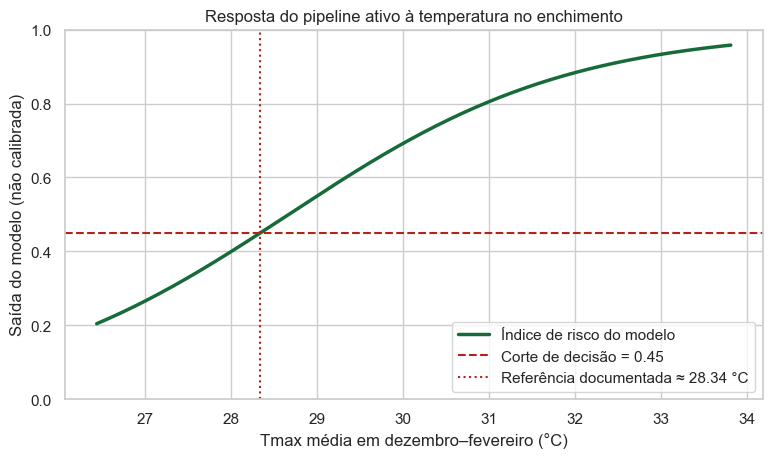

Coeficiente do modelo (escala padronizada): 0.6334; intercepto: -0.1304
O pipeline completo faz a padronização antes do classificador; os coeficientes são, portanto, na escala padronizada.


In [2]:
modelo_logistico = pipeline.named_steps["model"]
coeficiente = float(modelo_logistico.coef_[0, 0])
intercepto = float(modelo_logistico.intercept_[0])
if coeficiente <= 0:
    raise ValueError("A direção do coeficiente do artefato diverge da regra de temperatura documentada.")

temperaturas = np.linspace(dados[FEATURES[0]].min() - 0.5, dados[FEATURES[0]].max() + 0.5, 300)
grade = pd.DataFrame({FEATURES[0]: temperaturas})
probabilidades = pipeline.predict_proba(grade)[:, list(pipeline.classes_).index(1)]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(temperaturas, probabilidades, color="#176b3a", linewidth=2.5, label="Índice de risco do modelo")
ax.axhline(LIMIAR, color="#b42318", linestyle="--", label=f"Corte de decisão = {LIMIAR:.2f}")
ax.axvline(LIMIAR_C, color="#b42318", linestyle=":", label=f"Referência documentada ≈ {LIMIAR_C:.2f} °C")
ax.set(title="Resposta do pipeline ativo à temperatura no enchimento", xlabel="Tmax média em dezembro–fevereiro (°C)", ylabel="Saída do modelo (não calibrada)")
ax.set_ylim(0, 1)
ax.legend()
plt.show()
print(f"Coeficiente do modelo (escala padronizada): {coeficiente:.4f}; intercepto: {intercepto:.4f}")
print("O pipeline completo faz a padronização antes do classificador; os coeficientes são, portanto, na escala padronizada.")

## 2. Backtest expansivo no período de treino

Em cada origem, ajustamos uma cópia do pipeline usando somente linhas de safras anteriores à safra prevista. As primeiras origens são omitidas até existirem pelo menos oito safras anteriores. O limiar permanece em 0,45, conforme explicado no aviso metodológico inicial; não é reajustado olhando a safra prevista.

In [3]:
def probabilidade_classe_positiva(modelo, X):
    indice = list(modelo.classes_).index(1)
    return modelo.predict_proba(X)[:, indice]


previsoes_backtest = []
safras_treino = sorted(treino["safra"].unique())
for safra_validacao in safras_treino:
    safras_anteriores = [s for s in safras_treino if s < safra_validacao]
    if len(safras_anteriores) < MIN_SAFRAS_ANTERIORES:
        continue
    ajuste = treino.loc[treino["safra"].isin(safras_anteriores)]
    validacao = treino.loc[treino["safra"].eq(safra_validacao)]
    if ajuste[TARGET].nunique() != 2:
        continue
    modelo_origem = clone(pipeline)
    modelo_origem.fit(ajuste[FEATURES], ajuste[TARGET])
    prob = probabilidade_classe_positiva(modelo_origem, validacao[FEATURES])
    previsoes_backtest.append(
        validacao[["cod_municipio", "municipio", "safra", TARGET, FEATURES[0]]].assign(
            probabilidade=prob,
            alerta=(prob >= LIMIAR).astype(int),
            safra_inicio_treino=min(safras_anteriores),
            safra_fim_treino=max(safras_anteriores),
            n_safras_treino=len(safras_anteriores),
        )
    )

if not previsoes_backtest:
    raise ValueError("O backtest não gerou previsões; confira número de safras e a regra de mínimo histórico.")
backtest = pd.concat(previsoes_backtest, ignore_index=True).rename(columns={TARGET: "observado"})
backtest["erro"] = np.select(
    [backtest["observado"].eq(1) & backtest["alerta"].eq(0), backtest["observado"].eq(0) & backtest["alerta"].eq(1)],
    ["Falso negativo", "Falso positivo"],
    default="Acerto",
)
print(f"Previsões walk-forward: {len(backtest)} linhas, safras {backtest.safra.min()}–{backtest.safra.max()}")
print("Em cada linha, o modelo foi treinado somente com observações de safras anteriores àquela previsão.")
backtest.head()

Previsões walk-forward: 88 linhas, safras 2009–2018
Em cada linha, o modelo foi treinado somente com observações de safras anteriores àquela previsão.


,cod_municipio,municipio,safra,observado,tmax_enchimento,probabilidade,alerta,safra_inicio_treino,safra_fim_treino,n_safras_treino,erro
0,5105259,Lucas do Rio Verde,2009,0,28.415111,0.504525,1,2001,2008,8,Falso positivo
1,5105903,Nobres,2009,0,29.775667,0.587840,1,2001,2008,8,Falso positivo
2,5106224,Nova Mutum,2009,0,28.144778,0.487790,1,2001,2008,8,Falso positivo
3,5106240,Nova Ubiratã,2009,0,27.806000,0.466862,1,2001,2008,8,Falso positivo
4,5107768,Santa Rita do Trivelato,2009,0,28.709222,0.522718,1,2001,2008,8,Falso positivo


## 3. Métricas do backtest por safra

Acurácia é a fração total de classificações corretas. Recall mede quantas quebras reais foram alertadas; precisão mede quantos alertas correspondiam a quebras. Como uma quebra não detectada é considerada cinco vezes mais custosa que um falso alarme, também mostramos `custo = 5 × FN + FP`. Safras sem positivos não têm recall/AUC definidos de forma informativa; o código apresenta zero para recall/precisão nesse caso e deixa AUC como não disponível.

In [4]:
def resumir(y, pred, prob=None):
    y = np.asarray(y, dtype=int)
    pred = np.asarray(pred, dtype=int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    auc = np.nan
    if prob is not None and np.unique(y).size == 2:
        auc = roc_auc_score(y, prob)
    return {
        "N": len(y), "VN": int(tn), "FP": int(fp), "FN": int(fn), "VP": int(tp),
        "Acurácia": accuracy_score(y, pred),
        "Recall": recall_score(y, pred, zero_division=0),
        "Precisão": precision_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "AUC": auc,
        "% alertas": np.mean(pred),
        "% quebras": np.mean(y),
        "Custo (5×FN+FP)": int(CUSTO_FN * fn + CUSTO_FP * fp),
    }


linhas_safra = []
for safra, grupo in backtest.groupby("safra", sort=True):
    linha = {"Safra": int(safra), **resumir(grupo["observado"], grupo["alerta"], grupo["probabilidade"])}
    linha["Treino até"] = int(grupo["safra_fim_treino"].iloc[0])
    linhas_safra.append(linha)
metricas_backtest_safra = pd.DataFrame(linhas_safra)
metricas_backtest = pd.DataFrame([resumir(backtest["observado"], backtest["alerta"], backtest["probabilidade"])], index=["Backtest agrupado"])
display(metricas_backtest_safra.round(3))
display(metricas_backtest.round(3))

,Safra,N,VN,FP,FN,VP,Acurácia,Recall,Precisão,F1,AUC,% alertas,% quebras,Custo (5×FN+FP),Treino até
0,2009,7,1,6,0,0,0.143,0.0,0.000,0.000,NaN,0.857,0.000,6,2008
1,2010,9,0,9,0,0,0.000,0.0,0.000,0.000,NaN,1.000,0.000,9,2009
2,2011,9,6,3,0,0,0.667,0.0,0.000,0.000,NaN,0.333,0.000,3,2010
3,2012,9,5,4,0,0,0.556,0.0,0.000,0.000,NaN,0.444,0.000,4,2011
4,2013,9,0,6,0,3,0.333,1.0,0.333,0.500,0.833,1.000,0.333,6,2012
5,2014,9,4,1,2,2,0.667,0.5,0.667,0.571,0.800,0.333,0.444,11,2013
6,2015,9,3,6,0,0,0.333,0.0,0.000,0.000,NaN,0.667,0.000,6,2014
7,2016,9,0,3,0,6,0.667,1.0,0.667,0.800,0.444,1.000,0.667,3,2015
8,2017,9,5,4,0,0,0.556,0.0,0.000,0.000,NaN,0.444,0.000,4,2016
9,2018,9,4,5,0,0,0.444,0.0,0.000,0.000,NaN,0.556,0.000,5,2017


,N,VN,FP,FN,VP,Acurácia,Recall,Precisão,F1,AUC,% alertas,% quebras,Custo (5×FN+FP)
Backtest agrupado,88,28,47,2,11,0.443,0.846,0.19,0.31,0.775,0.659,0.148,57


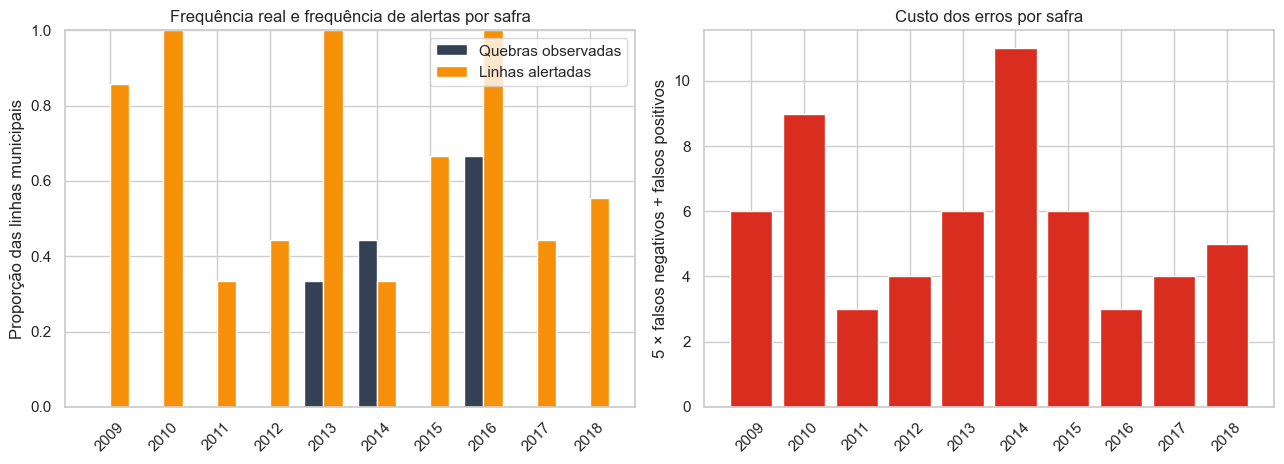

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(len(metricas_backtest_safra))
largura = 0.36
axes[0].bar(x - largura / 2, metricas_backtest_safra["% quebras"], width=largura, label="Quebras observadas", color="#344054")
axes[0].bar(x + largura / 2, metricas_backtest_safra["% alertas"], width=largura, label="Linhas alertadas", color="#f79009")
axes[0].set_xticks(x, metricas_backtest_safra["Safra"], rotation=45)
axes[0].set_ylim(0, 1)
axes[0].set_title("Frequência real e frequência de alertas por safra")
axes[0].set_ylabel("Proporção das linhas municipais")
axes[0].legend()
axes[1].bar(metricas_backtest_safra["Safra"].astype(str), metricas_backtest_safra["Custo (5×FN+FP)"], color="#d92d20")
axes[1].set_title("Custo dos erros por safra")
axes[1].set_ylabel("5 × falsos negativos + falsos positivos")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

## 4. Avaliação principal: teste temporal congelado 2019–2024

Agora usamos diretamente o pipeline serializado, que foi ajustado no treino completo. Esta etapa não refaz o ajuste do limiar nem do modelo. O teste tem poucas safras independentes; 54 linhas município-safra não equivalem a 54 safras independentes, pois municípios compartilham condições anuais.

In [6]:
prob_teste = probabilidade_classe_positiva(pipeline, teste[FEATURES])
pred_teste = (prob_teste >= LIMIAR).astype(int)
avaliacao_teste = teste[["cod_municipio", "municipio", "safra", TARGET, FEATURES[0]]].copy()
avaliacao_teste = avaliacao_teste.rename(columns={TARGET: "observado"})
avaliacao_teste["probabilidade"] = prob_teste
avaliacao_teste["alerta"] = pred_teste
avaliacao_teste["resultado"] = np.select(
    [avaliacao_teste["observado"].eq(1) & avaliacao_teste["alerta"].eq(0), avaliacao_teste["observado"].eq(0) & avaliacao_teste["alerta"].eq(1)],
    ["Falso negativo", "Falso positivo"], default="Acerto"
)

# Baselines simples para contextualizar o custo, não como modelos concorrentes treinados.
metricas_teste = resumir(avaliacao_teste["observado"], avaliacao_teste["alerta"], avaliacao_teste["probabilidade"])
comparacao = [{"Estratégia": "Regressão Logística ativa", **metricas_teste}]
for nome, pred in [("Nunca alertar", np.zeros(len(teste), dtype=int)), ("Alertar sempre", np.ones(len(teste), dtype=int))]:
    comparacao.append({"Estratégia": nome, **resumir(teste[TARGET], pred)})
comparacao_teste = pd.DataFrame(comparacao).set_index("Estratégia")
display(comparacao_teste.round(3))

sem_2024 = avaliacao_teste["safra"].ne(2024)
metricas_sem_2024 = resumir(
    avaliacao_teste.loc[sem_2024, "observado"],
    avaliacao_teste.loc[sem_2024, "alerta"],
    avaliacao_teste.loc[sem_2024, "probabilidade"],
)
display(pd.DataFrame([metricas_sem_2024], index=["Teste sem 2024"]).round(3))

# Regressão evita que alterações no notebook mudem silenciosamente a previsão oficial.
assert len(teste) == 54
assert (metricas_teste["VN"], metricas_teste["FP"], metricas_teste["FN"], metricas_teste["VP"]) == (13, 29, 3, 9)
assert np.isclose(metricas_teste["AUC"], 0.7281746031746033)
print("Checagem do resultado congelado passou: 13 VN, 29 FP, 3 FN, 9 VP; AUC ≈ 0,728.")

,N,VN,FP,FN,VP,Acurácia,Recall,Precisão,F1,AUC,% alertas,% quebras,Custo (5×FN+FP)
Estratégia,,,,,,,,,,,,,
Regressão Logística ativa,54,13,29,3,9,0.407,0.75,0.237,0.360,0.728,0.704,0.222,44
Nunca alertar,54,42,0,12,0,0.778,0.00,0.000,0.000,NaN,0.000,0.222,60
Alertar sempre,54,0,42,0,12,0.222,1.00,0.222,0.364,NaN,1.000,0.222,42


,N,VN,FP,FN,VP,Acurácia,Recall,Precisão,F1,AUC,% alertas,% quebras,Custo (5×FN+FP)
Teste sem 2024,45,13,28,3,1,0.311,0.25,0.034,0.061,0.341,0.644,0.089,43


Checagem do resultado congelado passou: 13 VN, 29 FP, 3 FN, 9 VP; AUC ≈ 0,728.


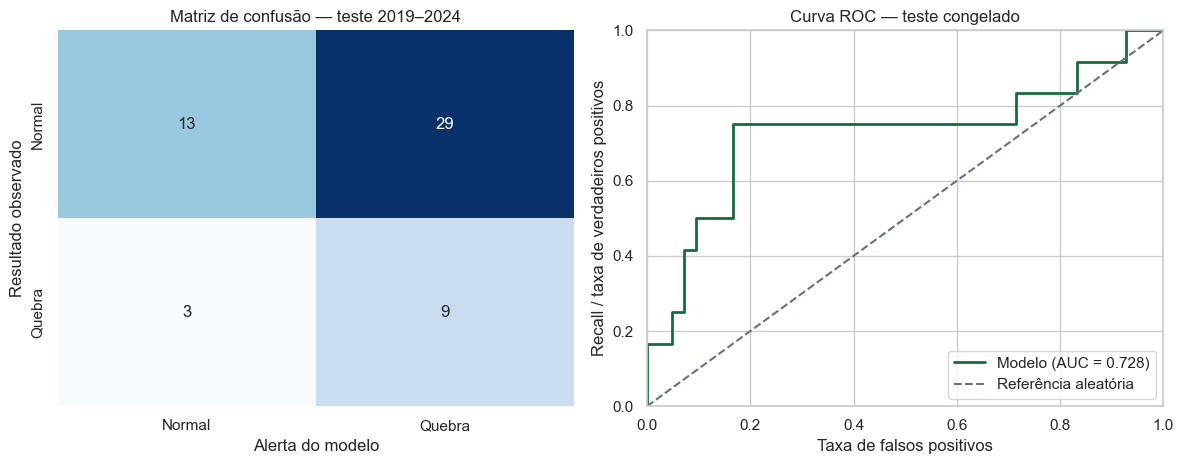

In [7]:
y_teste = avaliacao_teste["observado"].to_numpy(dtype=int)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
cm = confusion_matrix(y_teste, pred_teste, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0], xticklabels=["Normal", "Quebra"], yticklabels=["Normal", "Quebra"])
axes[0].set(title="Matriz de confusão — teste 2019–2024", xlabel="Alerta do modelo", ylabel="Resultado observado")
fpr, tpr, _ = roc_curve(y_teste, prob_teste)
axes[1].plot(fpr, tpr, color="#176b3a", linewidth=2, label=f"Modelo (AUC = {metricas_teste['AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], color="#667085", linestyle="--", label="Referência aleatória")
axes[1].set(title="Curva ROC — teste congelado", xlabel="Taxa de falsos positivos", ylabel="Recall / taxa de verdadeiros positivos", xlim=(0, 1), ylim=(0, 1))
axes[1].legend(loc="lower right")
fig.tight_layout()
plt.show()

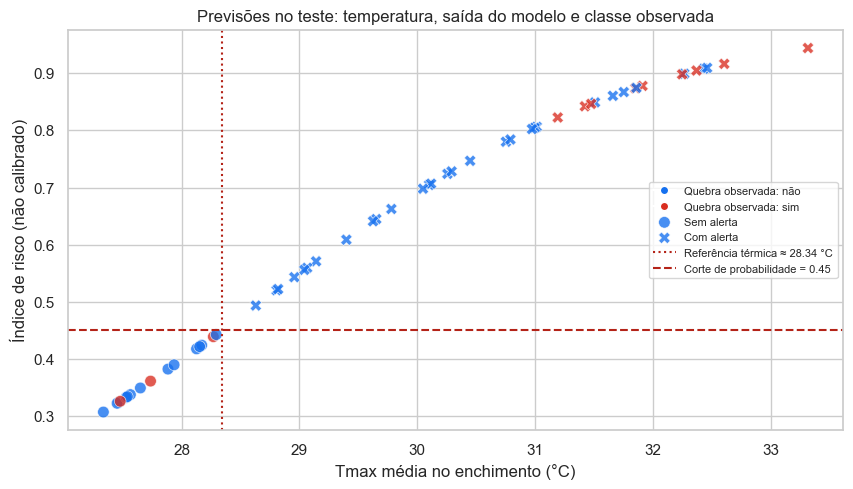

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.2))
cores = avaliacao_teste["observado"].map({0: "#1570ef", 1: "#d92d20"})
marcadores = avaliacao_teste["alerta"].map({0: "o", 1: "X"})
for marcador in ["o", "X"]:
    mask = marcadores.eq(marcador)
    ax.scatter(
        avaliacao_teste.loc[mask, FEATURES[0]],
        avaliacao_teste.loc[mask, "probabilidade"],
        c=cores.loc[mask], marker=marcador, s=70, alpha=0.78,
        label="Sem alerta" if marcador == "o" else "Com alerta",
        edgecolors="white", linewidths=0.5,
    )
ax.axvline(LIMIAR_C, color="#b42318", linestyle=":", label=f"Referência térmica ≈ {LIMIAR_C:.2f} °C")
ax.axhline(LIMIAR, color="#b42318", linestyle="--", label=f"Corte de probabilidade = {LIMIAR:.2f}")
ax.set(title="Previsões no teste: temperatura, saída do modelo e classe observada", xlabel="Tmax média no enchimento (°C)", ylabel="Índice de risco (não calibrado)")
from matplotlib.lines import Line2D
legenda_classes = [Line2D([0], [0], marker="o", color="w", markerfacecolor="#1570ef", label="Quebra observada: não"), Line2D([0], [0], marker="o", color="w", markerfacecolor="#d92d20", label="Quebra observada: sim")]
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=legenda_classes + handles, loc="best", fontsize=8)
plt.show()

## 5. Onde erra? Falsos positivos e falsos negativos

Um falso positivo é um município-safra alertado sem quebra observada; um falso negativo é uma quebra observada sem alerta. A listagem abaixo conserva município, safra, temperatura e índice do modelo para facilitar a conferência com o contexto agronômico. Ela não transforma correlação em causa.

In [9]:
colunas_erro = ["municipio", "safra", FEATURES[0], "probabilidade", "observado", "alerta"]
falsos_positivos = avaliacao_teste.loc[avaliacao_teste["resultado"].eq("Falso positivo"), colunas_erro].sort_values(["safra", "municipio"])
falsos_negativos = avaliacao_teste.loc[avaliacao_teste["resultado"].eq("Falso negativo"), colunas_erro].sort_values(["safra", "municipio"])
print(f"Falsos positivos: {len(falsos_positivos)}")
display(falsos_positivos.round({FEATURES[0]: 2, "probabilidade": 3}))
print(f"Falsos negativos: {len(falsos_negativos)}")
display(falsos_negativos.round({FEATURES[0]: 2, "probabilidade": 3}))

print("Erros por safra no teste:")
display(
    avaliacao_teste.groupby("safra").agg(
        municipios=("cod_municipio", "size"),
        quebras_observadas=("observado", "sum"),
        alertas=("alerta", "sum"),
        falsos_positivos=("resultado", lambda s: int(s.eq("Falso positivo").sum())),
        falsos_negativos=("resultado", lambda s: int(s.eq("Falso negativo").sum())),
    )
)

Falsos positivos: 29


,municipio,safra,tmax_enchimento,probabilidade,observado,alerta
9,Ipiranga do Norte,2019,28.63,0.493,0,1
48,Lucas do Rio Verde,2019,30.10,0.705,0,1
72,Nobres,2019,30.26,0.724,0,1
96,Nova Mutum,2019,30.45,0.747,0,1
119,Nova Ubiratã,2019,29.65,0.645,0,1
138,Santa Rita do Trivelato,2019,30.12,0.707,0,1
162,Sorriso,2019,29.04,0.556,0,1
186,Tapurah,2019,28.96,0.543,0,1
10,Ipiranga do Norte,2020,28.81,0.520,0,1
25,Itanhangá,2020,29.14,0.571,0,1


Falsos negativos: 3


,municipio,safra,tmax_enchimento,probabilidade,observado,alerta
51,Lucas do Rio Verde,2022,28.27,0.439,1,0
99,Nova Mutum,2022,27.74,0.361,1,0
189,Tapurah,2022,27.48,0.326,1,0


Erros por safra no teste:


,municipios,quebras_observadas,alertas,falsos_positivos,falsos_negativos
safra,,,,,
2019,9,0,8,8,0
2020,9,0,9,9,0
2021,9,1,9,8,0
2022,9,3,1,1,3
2023,9,0,2,2,0
2024,9,8,9,1,0


## 6. Leitura final e limites

O teste congelado tem 54 observações município-safra, mas somente seis safras compartilhadas entre os municípios. A acurácia não deve ser interpretada sem comparar as classes, o recall, a precisão, o custo e os erros por safra. O teste completo também é sensível a 2024; por isso, a tabela sem 2024 é um diagnóstico de sensibilidade, não um novo conjunto de teste independente.

O artefato ativo ainda usa apenas temperatura máxima média de dezembro a fevereiro. Também foi avaliada uma LogReg candidata com cinco sinais: Tmax média, dias com `GWETROOT < 0,70`, dias com Tmax diária ≥ 35 °C, precipitação acumulada e maior sequência com chuva diária < 1 mm. Ela obteve custo 32 e AUC 0,778 no teste, melhores que o ativo (44 e 0,728), mas custo 61 na validação expansiva (ativo: 25) e custo 31 sem 2024, ainda acima do baseline nunca alertar (20). Por isso, não foi promovida e não substituiu o pipeline ativo. As métricas e resultados por safra estão em `models/s6_comparacao_multivariavel.csv` e `models/s6_metricas_por_safra.csv`.

Mesmo com as variáveis adicionais, o modelo pode não detectar quebras por doenças, excesso de chuva ou outros mecanismos. Não use a saída isoladamente para decisões de crédito, seguro ou manejo.

### Referências de reprodutibilidade

- Pipeline ativo: `models/pipeline_final.joblib`
- Limiar congelado: `models/limiar_congelado.json`
- Base: `data/processed/dados_modelo_s4.csv`
- Seleção/validação e definição do limiar: notebooks 08, 11 e 12
- Teste congelado e Model Card: notebook 13 e `docs/Model_Card.md`
- Experimento separado multivariável (não implantado): `src/experimento_multivariavel.py`
- Comparação de nove classificadores com cinco variáveis: `src/comparacao_modelos_multivariaveis.py` e resultados `models/s7_*.csv`